# This notebook calculates 0-D RE evolution for ARC

In [3]:
import sys
RE_path = './'
sys.path.insert(1, RE_path)

In [4]:
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *

# Constants

In [5]:
importlib.reload(RE)
from RE import *

# Constants - ARC V2E
R0 = 4.62 # Major Radius, [m]
a = 1.18 # Minor Radius, [m]
ni = 2e20 # ion density in plasma fuel, per m**3
L = 1.25e-6 # inductance [H]
k = 1.55 # elongation

# MGI ion densities
nD = 1e-11 # Diuterium 7.1e21 < nD (m-3) < 3.5e22
nNe = 1e-11 # Neon 7e20, 3.5e21

# Initial Conditions
I0 = 12.0e6 # [A], Initial Plasma Current


## Prescribe the TQ ##
T0 = 11e3 # eV, initial temperature
Tf = 10 # eV
t0 = 1e-3 # TQ time

# Estimated HT seed
eta0 = 0.51 * getTransSpitzerResistivity(15,T0,1) * 0.01 # Ohm-m
E0 = eta0*(I0) / (np.pi * a**2 * k) # Parallel E-field [N/C]





Expected HT Seed [kA] = 4.91e-12


# Define the ODEs

In [4]:
def dYdt(t,Y,primary_sources=[1,1,1],iAvalanche=1,nD=1e-10,nNe=1e-10):
    # Y[0] = Plasma Current [A]
    # Y[1] = RE current [A]
    # Y[2] = RE Kinetic Energy [J]
    # primary_sources = [iDreicer, iTritium, iCompton], 0 = off
    # iDreicer = 1 Classical; 2 = Hesslow NN
    # iAvalanche = 1 Rosenbluth-PUtvinski, 2 Chiu-Harvey, 0 = off
    
    Ip, Ir, Wkin = Y
    
    iDreicer, iTritium, iCompton = primary_sources
    
    # Prescribed Thermal Quench
    T = (T0 - Tf)* np.exp(-t/t0) + Tf # eV, Time-varying temperature
    # ZNe = getZbarTF(10, 20, SI2cgs(20*nNe*const.m_p,'Mass Density'), T)[0] # caluclate ionization level using LTE Thomas-Fermi model
    ZNe = getNeZ(T) # Using ADAS Coronal Eqm. Model
    ne = 1 * ni + 1 * nD + ZNe * nNe # Total free electron density, per cubic m, assumes hydrogenic species are fully ionized
    Zeff = (ni + nD + nNe * ZNe**2) / (ni + nD + nNe * ZNe) # Effective ionization of plasma
    ntot = ni + nD + 10 * nNe # Total free + bound electron density, per cubic m
    
    lnA = getCoulombLog(ne,T)
    eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
    Epar = eta*(Ip - Ir) / (np.pi * a**2 * k) # Parallel E-field [N/C]
    Ec = getConnorHastieField(ne,lnA) # Connor-Hastie Critical Field, [N/C]
    Ed = getDreicerField(ne,lnA,T) # [N/C] Dreicer Field
    E_star = Epar / Ec # Normalized field [-]
    
    
    # Primary Sources
    
    if iDreicer == 1:
        SD = getDreicerSource(E_star,ne,lnA,Zeff,T) # per m3 per s, Classical Dreicer
    elif iDreicer == 2:
        SD = getDreicerRateHesslow(ni,nNe,18,ZNe,Epar/Ed,T)
    else:
        SD = 0
    
    
    ST = getTritBetaDecay(0.5*ni,E_star)  # per m3 per s
    
    if T >= 2.6e3:
        SC = getComptonSource(E_star,ntot,'ARC-P') # Use Prompt Flux
    else:
        SC =  getComptonSource(E_star,ntot,'ARC-NP') # Use Non Prompt Flux
        
    # Total Primary Contribution
    S =  SD + iTritium * ST + iCompton * SC # per m3 per s
    j_primary = S * const.c * const.e # A/m**2/s
        
    # Avalanche
    if iAvalanche == 0:
        Yav = 0;
    elif iAvalanche == 1:
         Yav = (ntot/ne) * iAvalanche * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second
    elif iAvalanche == 2:
        Yav =  (ntot/ne) * get_avalance_growth_rate_CH(E_star,ne,0/R0,lnA,Zeff) # per second
    
    dIpdt = -2 * np.pi * R0 * Epar / L # [A/s]
    dIrdt = j_primary * np.pi * a**2 + Yav * Ir # [A/s]
    dWkindt = 2 * np.pi * R0 * Ir * Epar
    
    return [dIpdt, dIrdt, dWkindt]

# Solve

In [5]:
from scipy.integrate import solve_ivp
t = np.linspace(0,15e-3,10000) # times to solve at [s]

iDreicer, iTritium, iCompton = 0, 0, 0
iAvalanche = 1
Ir0 = 1e3 # [A], Initial RE Current
primary_sources=[iDreicer, iTritium, iCompton] # [iDreicer, iTritium, iCompton]
sol = solve_ivp(dYdt, t_span=(0,max(t)), y0 = [I0,Ir0,0],t_eval=t,args=(primary_sources,iAvalanche,nD,nNe))

# Show Solution

Plateau Current [MA] = 4.164


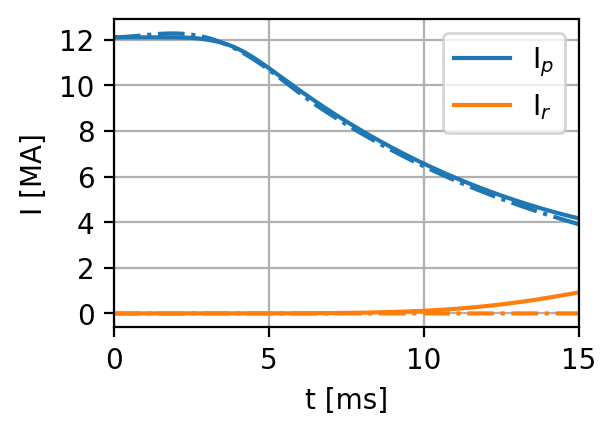

In [6]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
axs.plot(sol.t*1e3,sol.y[0]/1e6,label='I$_p$')
axs.plot(sol.t*1e3,sol.y[1]/1e6,label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
# axs.set_ylim([0,12])
axs.set_yticks(np.arange(0,13,2))
axs.legend()
axs.set_xlim([0,np.max(sol.t*1e3)])
# axs.set_yscale('log')

print('Plateau Current [MA] = %1.3f'%(sol.y[0][-1]/1e6))


# Solution with Ir = 0
sol2 = solve_ivp(dYdt, t_span=(0,max(t)), y0 = [I0,0,0],t_eval=t,args=(primary_sources,iAvalanche,nD,nNe))
axs.plot(sol2.t*1e3,sol2.y[0]/1e6,'-.',color='tab:blue')
axs.plot(sol2.t*1e3,sol2.y[1]/1e6,'-.',color='tab:orange')

# RE Energy

Plateau Energy [MJ] = 3.346
Average RE Energy [MeV] = 3.768


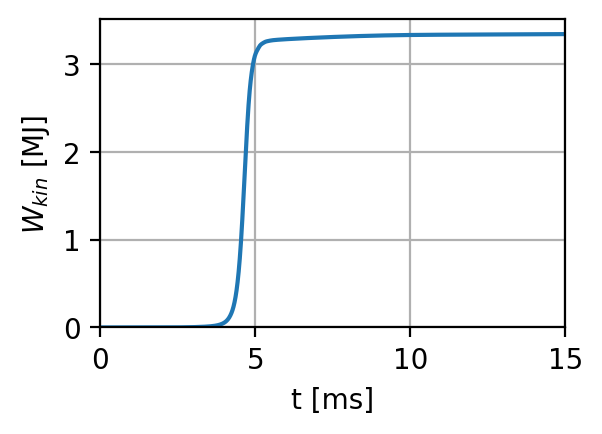

In [25]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
axs.plot(sol.t*1e3,sol.y[2]/1e6)
axs.set_xlabel('t [ms]')
axs.set_ylabel('$W_{kin}$ [MJ]')
axs.grid()
axs.set_ylim(ymin=0)
axs.set_xlim([0,np.max(sol.t*1e3)])
# axs.set_yscale('log')

print('Plateau Energy [MJ] = %1.3f'%(sol.y[2][-1]/1e6))

N = sol.y[1][-1] * (2 * np.pi * R0) / (const.e * const.c)
avg_energy = sol.y[2][-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))

# Show detailed reults

/var/folders/yx/1xzcdppn0xxd5w6bf_xnbgrw0000gn/T/ipykernel_29394/1142472173.py:85: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  axs[2,1].set_yscale('log')


max E/ED= 0.0009097825315089071
max E/ECH= 76.96841893233332
Ed/ECH= 102199.7899609885
max SD=0
max SC=0
max ST==0


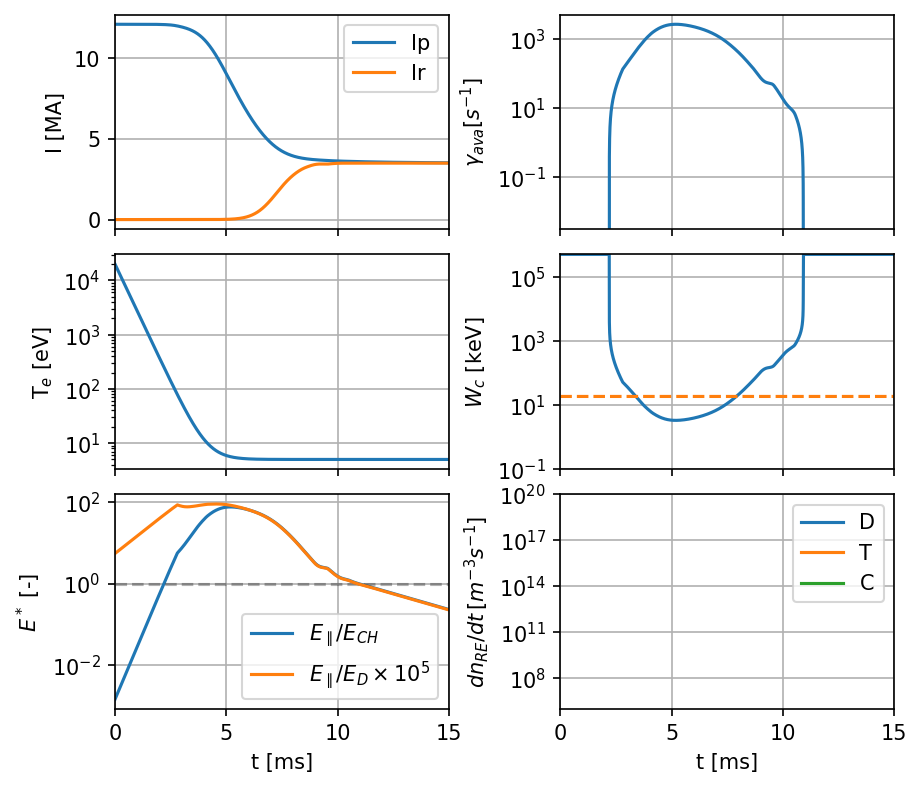

In [11]:
Ip = sol.y[0]
Ir = sol.y[1]

T = (T0 - Tf)* np.exp(-t/t0) + Tf # eV, Time-varying temperature
ZNe = getNeZ(T) # Using ADAS Coronal Eqm. Model
ne = 1 * ni + 1 * nD + ZNe * nNe # Total free electron density, per cubic m, assumes hydrogenic species are fully ionized
Zeff = (ni + nD + nNe * ZNe**2) / (ni + nD + nNe * ZNe) # Effective ionization of plasma
ntot = ni + nD + 10 * nNe # Total free + bound electron density, per cubic m
lnA = getCoulombLog(ne,T)
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
Epar = eta*(Ip -Ir) / (np.pi * a**2 * k) # Parallel E-field [N/C]
Ec = getConnorHastieField(ne,lnA) # [N/C]
Ed = getDreicerField(ne,lnA,T) # [N/C]
E_star = Epar / Ec # Normalized field [-]
Wc = getCriticalRunawayEnergy(E_star) / const.eV # eV

# Sources
if iDreicer == 1:
    SD = getDreicerSource(E_star,ne,lnA,Zeff,T) # per m3 per s, Classical Dreicer
elif iDreicer == 2:
    SD = getDreicerRateHesslow(ni,nNe,18,ZNe,Epar/Ed,T)
else:
    SD = np.zeros_like(E_star)

if iTritium:
    ST = getTritBetaDecay(0.5*ni,E_star)  # per m3 per s
else:
    ST = 0 * SD
if iCompton:
    SC =  getComptonSource(E_star,ntot,'ARC-P') 
    SC[np.where(T<2.6e3)] = 1e0 * getComptonSource(E_star[np.where(T<2.6e3)],ntot,'ARC-NP') 
else:
    SC = 0 * SD

Yav =  (ntot / ne) * get_avalance_growth_rate_RP2(E_star,ne,0/R0,lnA,Zeff) # per second

# Plot
fig, axs = plt.subplots(3,2,sharex=True,figsize=(6,5),dpi=150)

axs[0,0].plot(t*1e3,Ip/1e6,label='Ip')
axs[0,0].plot(t*1e3,Ir/1e6,label='Ir')
axs[0,0].set_ylabel('I [MA]')
axs[0,0].legend()
# axs[0,0].plot([t0*1e3]*2,[0,10],'--',color='k',alpha=0.2)
# axs[0,0].plot([2*t0*1e3]*2,[0,10],'--',color='k',alpha=0.2)
# axs[0,0].plot([4*t0*1e3]*2,[0,10],'--',color='k',alpha=0.2)
# axs[0,0].plot([16*t0*1e3]*2,[0,10],'--',color='k',alpha=0.2)

axs[1,0].plot(t*1e3,T)
# axs[1,0].plot([t0*1e3]*2,[1,20e3],'--',color='k',alpha=0.3)
# axs[1,0].plot([2*t0*1e3]*2,[1,20e3],'--',color='k',alpha=0.3)
# axs[1,0].plot([4*t0*1e3]*2,[1,20e3],'--',color='k',alpha=0.3)
# axs[1,0].plot([16*t0*1e3]*2,[1,20e3],'--',color='k',alpha=0.3)
axs[1,0].set_ylabel('T$_e$ [eV]')
axs[1,0].set_yscale('log')

axs[2,0].plot(t*1e3,E_star,label='$E_{\parallel}/E_{CH}$')
axs[2,0].plot([0,t.max()*1e3],[1,1],'--',color='k',alpha=0.3)
axs[2,0].plot(t*1e3,Epar/Ed*1e5,label='$E_\parallel/E_D \\times 10^5$')
axs[2,0].set_ylabel('$E^*$ [-]')
axs[2,0].set_yscale('log')
axs[2,0].legend()



axs[0,1].plot(t*1e3,Yav)
axs[0,1].set_ylabel('$\gamma_{ava}  [s^{-1}]$')
axs[0,1].set_yscale('log')

axs[1,1].plot(t*1e3,Wc/1e3)
axs[1,1].plot(t*1e3,18.7*np.ones_like(t),'--')
axs[1,1].set_ylabel('$W_c$ [keV]')
axs[1,1].set_yscale('log')
axs[1,1].set_ylim([1e-1,1e4])
axs[1,1].set_ylim(ymax=getCriticalRunawayEnergy(1) / const.eV / 1e3)

axs[2,1].plot(t*1e3,SD,label='D')
axs[2,1].plot(t*1e3,ST,label='T')
axs[2,1].plot(t*1e3,SC,label='C')
# axs[2,1].plot([t0*1e3]*2,[1e8,1e12],'--',color='k',alpha=0.2)
# axs[2,1].plot([2*t0*1e3]*2,[1e8,1e12],'--',color='k',alpha=0.2)
# axs[2,1].plot([4*t0*1e3]*2,[1e8,1e12],'--',color='k',alpha=0.2)
# axs[2,1].plot([16*t0*1e3]*2,[1e8,1e12],'--',color='k',alpha=0.2)
axs[2,1].set_ylabel('$dn_{RE}/dt \, [m^{-3}s^{-1}]$')
axs[2,1].set_yscale('log')
axs[2,1].set_ylim([1e6,1e20])
axs[2,1].legend()


fig.tight_layout(pad=0.5)

for i in range(axs.shape[0]):
    for j in range(axs.shape[1]):
        axs[i,j].grid()
        axs[i,j].set_xlim([0,np.max(t*1e3)])
        
axs[-1,0].set_xlabel('t [ms]')    
axs[-1,1].set_xlabel('t [ms]')  

print('max E/ED=',np.max(Epar/Ed))
print('max E/ECH=',np.max(E_star))
print('Ed/ECH=',np.max(Ed/Ec))
print('max SD=%1.3g'%np.max(SD))
print('max SC=%1.3g'%np.max(SC))
print('max ST==%1.3g'%np.max(ST))

# Compton Spectrum

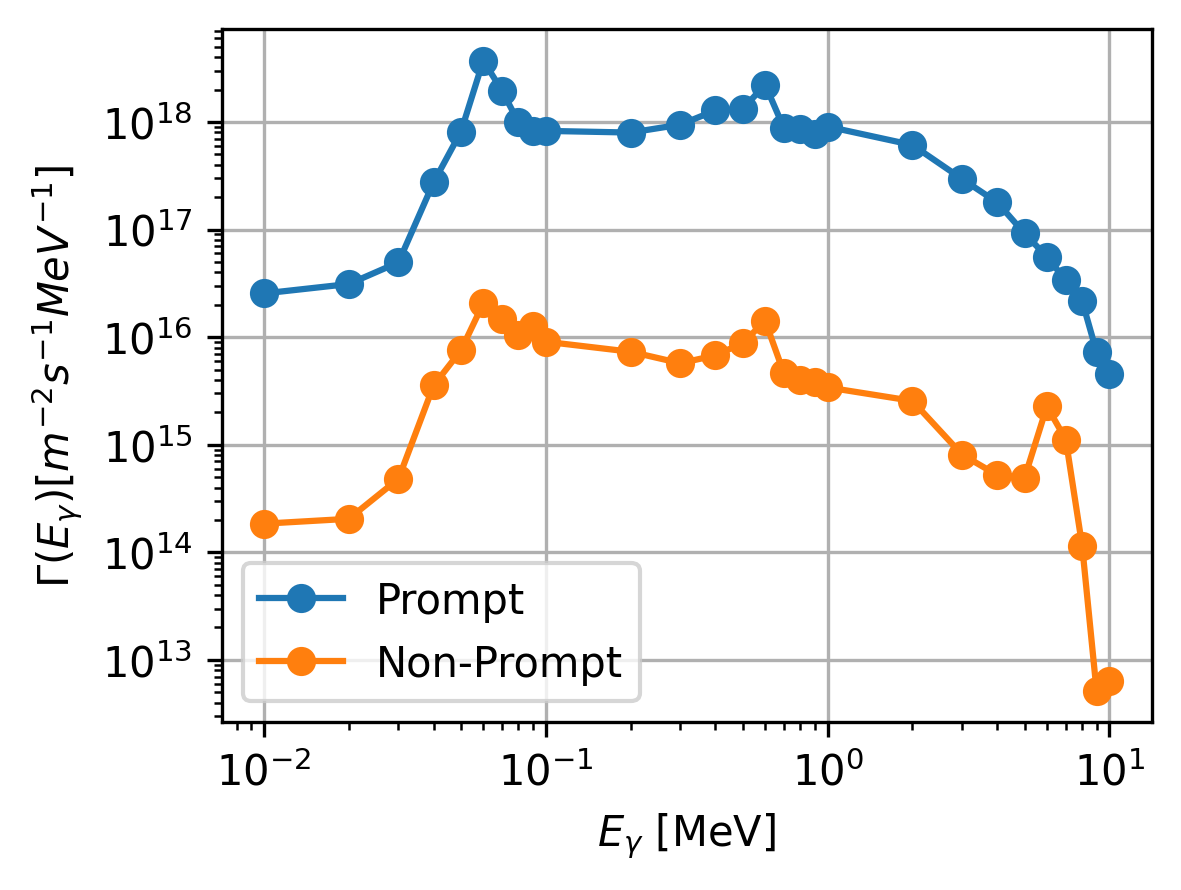

In [28]:
fig, axs = plt.subplots(1,1,dpi=300,figsize=(4,3),sharex=True)

data = np.loadtxt('./data/ARC_Prompt_Gamma_Flux.csv')
f = interp1d(data[0,:],data[1,:],fill_value="extrapolate")
# Gamma = f(E_gamma) # [#/m**2/s/MeV]

axs.plot(data[0,:],data[1,:],'-o',label='Prompt')

data = np.loadtxt('./data/ARC_NonPrompt_Gamma_Flux.csv')
f = interp1d(data[0,:],data[1,:],fill_value="extrapolate")
# Gamma = 1e-3 * f(E_gamma) # [#/m**2/s/MeV]

axs.plot(data[0,:],data[1,:],'-o',label='Non-Prompt')


axs.set_yscale('log')
axs.set_xscale('log')
    
axs.set_ylabel('$\Gamma(E_\gamma) [m^{-2}s^{-1}MeV^{-1}]$')
axs.set_xlabel('$E_{\gamma}$ [MeV]')
axs.grid()
axs.legend()


Max Prompt Rate = 5.78e-11 [per s]
Max Non-Prompt Rate = 3.39e-13 [per s]


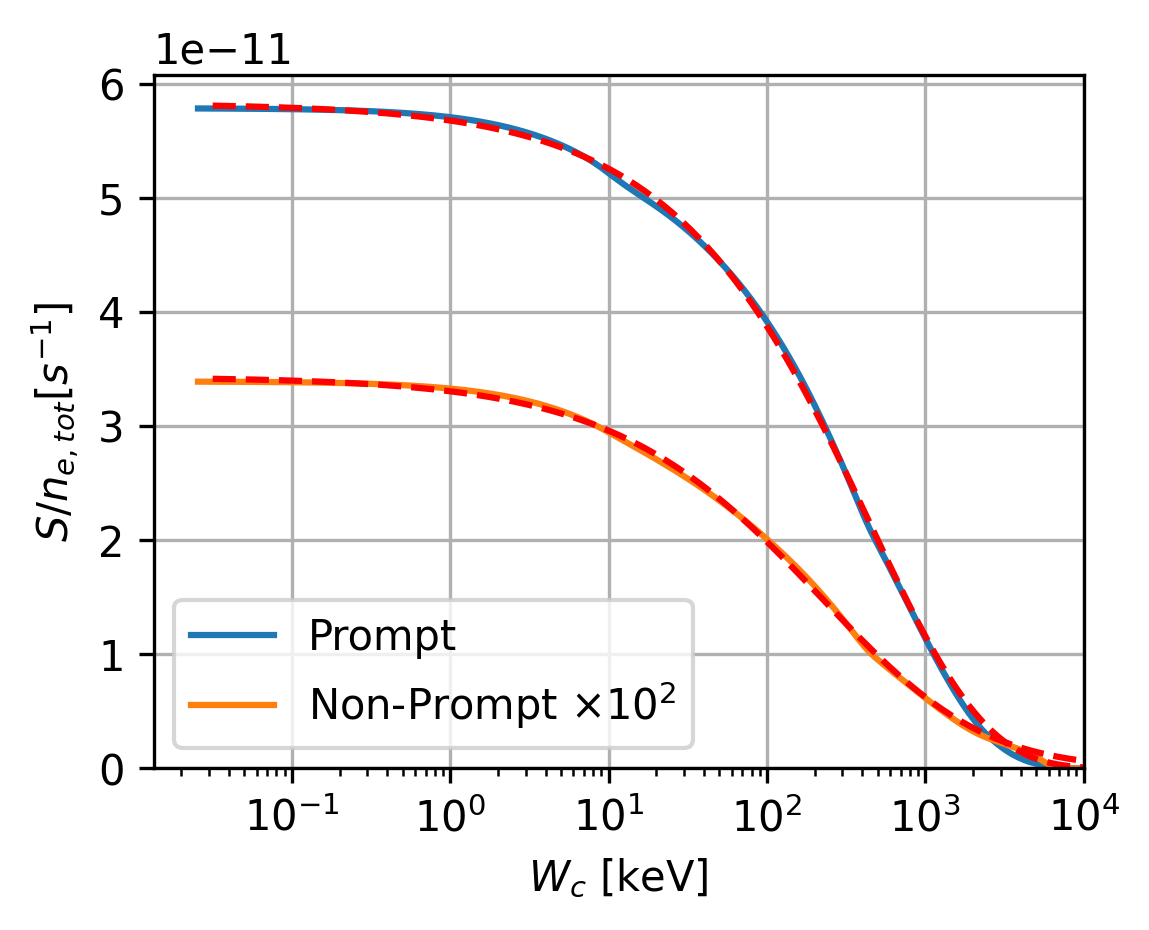

In [41]:
# Integrated rate


E_star = np.logspace(0.001,4,10000)
Wc = RE.getCriticalRunawayEnergy(E_star) / const.eV / 1e3 # keV
ne = 1
rate_NP = RE.getComptonSource(E_star,ne,device='ARC-NP') # per s
rate_P = RE.getComptonSource(E_star,ne,device='ARC-P') # per s

print('Max Prompt Rate = %1.3g [per s]'%(np.max(rate_P)))
print('Max Non-Prompt Rate = %1.3g [per s]'%(np.max(rate_NP)))


fig, axs = plt.subplots(1,1,dpi=300,figsize=(4,3),sharex=True)
axs.plot(Wc,rate_P,label='Prompt')
axs.plot(Wc,rate_NP*1e2,label='Non-Prompt $\\times 10^2$')
axs.set_xlabel('$W_c$ [keV]')
axs.set_ylabel('$S/n_{e,tot} [s^{-1}]$')
axs.set_xscale('log')
# axs.set_yscale('log')
axs.set_ylim(ymin=0)
axs.set_xlim(xmax=1e4)
axs.grid()
axs.legend()

# Fits
def fn(x, A, K, x0, nu):
    # K: Plateau height
    # A: Steepness
    # x0: Inflection point
    # nu: Asymmetry parameter (controls the long tail)
    return K / ((1 + np.exp(A * (x - x0))) ** nu)

xx = np.log(np.logspace(-1.5,4,200))

# Prompt
A, K, x0, nu = 5.972017e-01, 5.825923e-11, 2.330671e+01, 2.892493e+04 
yy = fn(xx,A,K,x0,nu)

axs.plot(np.exp(xx),yy,'--r')

# Non-Prompt
A, K, x0, nu = 6.067515e-01, 3.429507e-13,6.844332e+00, 2.388922e+00
yy = fn(xx,A,K,x0,nu)

axs.plot(np.exp(xx),yy*1e2,'--r')


A = 6.067515e-01 ± 1.185353e-03
K = 3.429507e-13 ± 5.492682e-17
x0 = 6.844332e+00 ± 3.035800e-02
nu = 2.388922e+00 ± 3.376636e-02


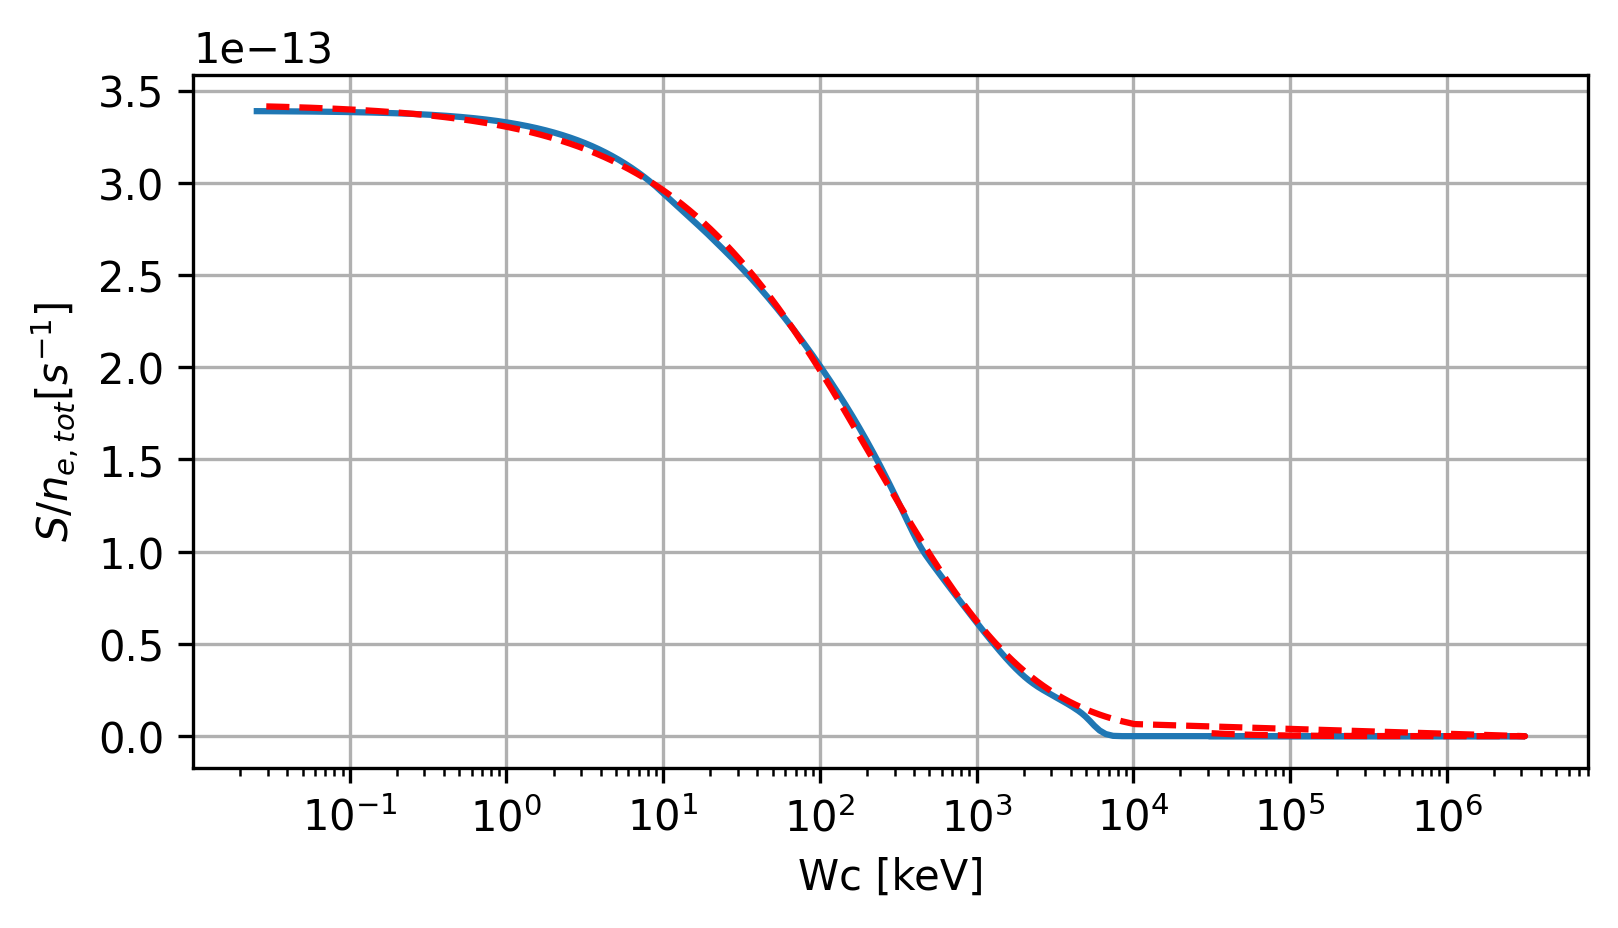

In [31]:
# Fits

E_star = np.logspace(0.001,4,10000)
Wc = RE.getCriticalRunawayEnergy(E_star) / const.eV / 1e3 # keV
ne = 1
rate = RE.getComptonSource(E_star,ne,device='ARC-NP')
# Create 500 heavily weighted tail points
Wc_tail = np.logspace(4.5, 6.5, 500)
rate_tail = np.zeros(500)

Wc = np.hstack([Wc_tail, Wc])
rate = np.hstack([rate_tail, rate])

fig, axs = plt.subplots(1,1,dpi=300,figsize=(6,3))
axs.plot(Wc, rate,'-' )
axs.set_xlabel('Wc [keV]')
axs.set_ylabel('$S/n_{e,tot} [s^{-1}]$')
axs.set_xscale('log')
axs.grid()
# axs.set_ylim(ymin=0)

# fit
from scipy.optimize import curve_fit
# def fn(x,A,B,x0,c):
#     return B * np.tanh(A * (x - x0)) + c

def fn(x, A, K, x0, nu):
    # K: Plateau height
    # A: Steepness
    # x0: Inflection point
    # nu: Asymmetry parameter (controls the long tail)
    return K / ((1 + np.exp(A * (x - x0))) ** nu)

x = np.log(Wc)
y = rate

initial_guess = [1.0, np.max(rate), np.median(x), 1.0]
popt, pcov = curve_fit(fn, x, y, p0=initial_guess, maxfev=10000)

axs.plot(Wc,fn(x,*popt),'r--')


perr = np.sqrt(np.diag(pcov))
for name, val, err in zip(['A', 'K', 'x0', 'nu'], popt, perr):
    print(f"{name} = {val:.6e} ± {err:.6e}")


A = 5.972017e-01 ± 3.652292e-04
K = 5.825923e-11 ± 5.293869e-15
x0 = 2.330671e+01 ± 7.699481e+00
nu = 2.892493e+04 ± 1.329830e+05


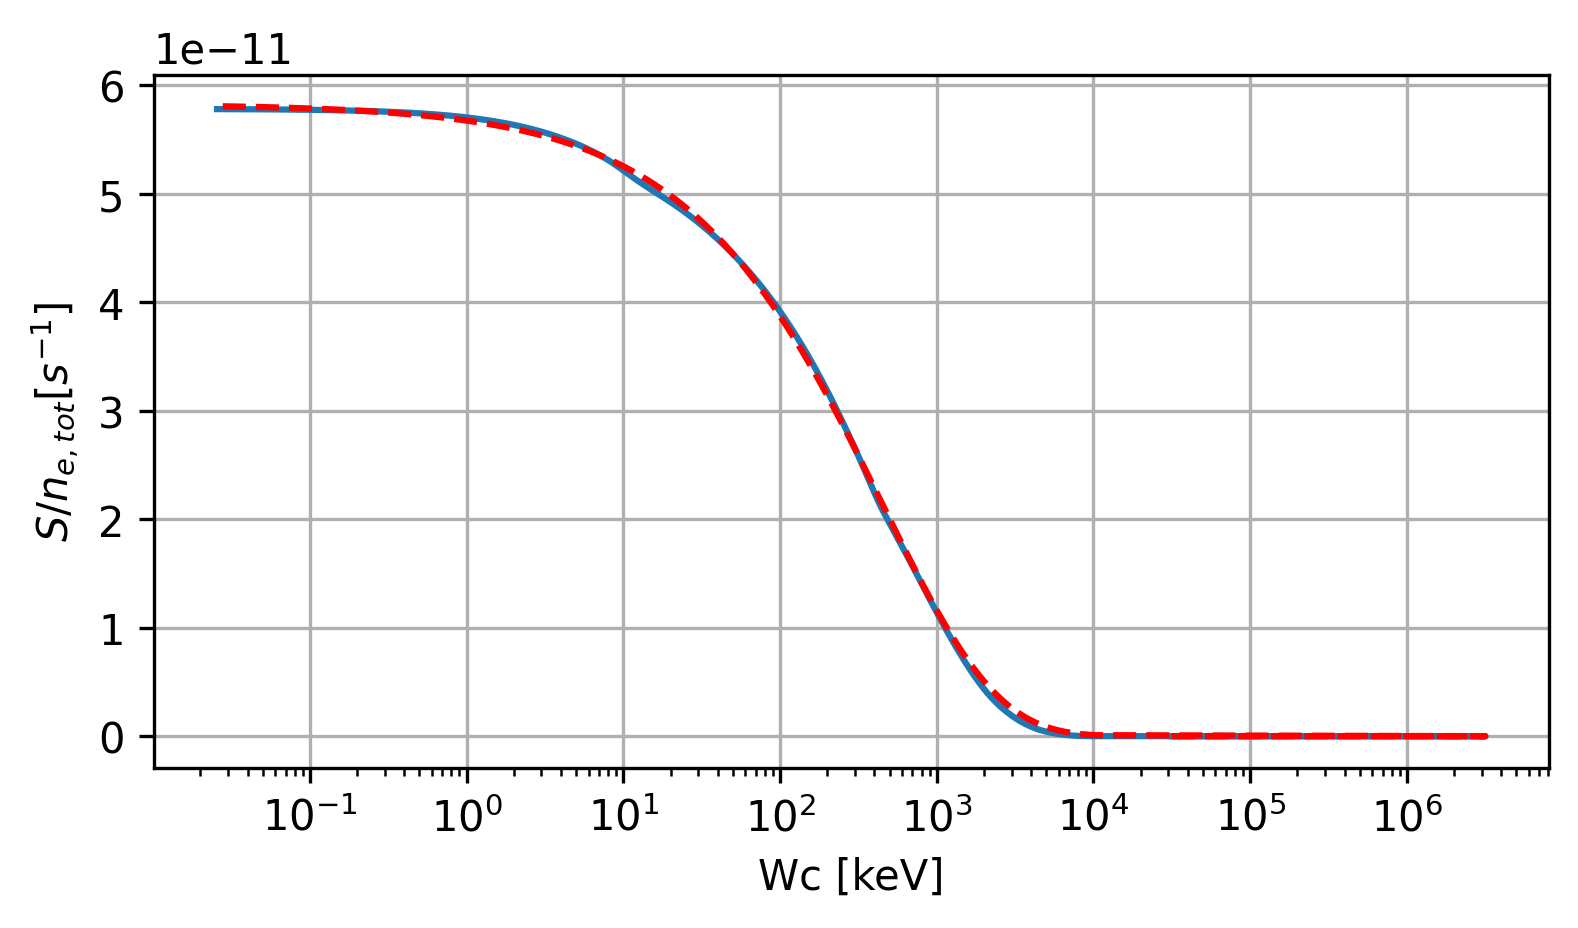

In [32]:
# Integrated rate

E_star = np.logspace(0.001,4,10000)
Wc = RE.getCriticalRunawayEnergy(E_star) / const.eV / 1e3 # keV
ne = 1
rate = RE.getComptonSource(E_star,ne,device='ARC-P')

# Create 500 heavily weighted tail points
Wc_tail = np.logspace(4.5, 6.5, 500)
rate_tail = np.zeros(500)

Wc = np.hstack([Wc_tail, Wc])
rate = np.hstack([rate_tail, rate])

fig, axs = plt.subplots(1,1,dpi=300,figsize=(6,3))
axs.plot(Wc, rate,'-' )
axs.set_xlabel('Wc [keV]')
axs.set_ylabel('$S/n_{e,tot} [s^{-1}]$')
axs.set_xscale('log')
axs.grid()
# axs.set_ylim(ymin=0)

# fit
from scipy.optimize import curve_fit
# def fn(x,A,B,x0):
#     return B * np.tanh(A * (x - x0)) + B

def fn(x, A, K, x0, nu):
    # K: Plateau height
    # A: Steepness
    # x0: Inflection point
    # nu: Asymmetry parameter (controls the long tail)
    return K / ((1 + np.exp(A * (x - x0))) ** nu)



x = np.log(Wc)
y = rate

initial_guess = [1.0, np.max(rate), np.median(x), 1.0]

popt, pcov = curve_fit(fn, x, y, p0=initial_guess, maxfev=10000)

axs.plot(Wc,fn(x,*popt),'r--')


perr = np.sqrt(np.diag(pcov))
for name, val, err in zip(['A', 'K', 'x0', 'nu'], popt, perr):
    print(f"{name} = {val:.6e} ± {err:.6e}")
